### 4.4 Definição do Hardware

In [1]:
# Verificar o status da GPU
!nvidia-smi

Sat Jul 25 13:25:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 4.5 Configuração do Ambiente (YOLOv8 e Dependências)

In [2]:
# Instala o motor Ultralytics (que roda YOLOv8 e YOLO11)
!pip install ultralytics
import ultralytics

# Verifica se o Colab te deu a placa de vídeo (GPU)
ultralytics.checks()

Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 46.7/112.6 GB disk)


### Conexão com a Nuvem (Google Drive)

In [3]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets (Pipeline MLOps Automático)

In [4]:
import shutil
import yaml
import os

# 1. Caminhos
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Yolo_dataset.zip"
pasta_local_vm = "/content/Yolo_dataset"
yaml_path = f"{pasta_local_vm}/data.yaml"

# 2. Criar a pasta para não espalhar os arquivos
os.makedirs(pasta_local_vm, exist_ok=True)

# 3. Automação MLOps (Verifica se a pasta de imagens existe)
if not os.path.exists(f"{pasta_local_vm}/images"):
    print("🚚 1. Copiando o ZIP do Drive para o SSD da VM...")
    shutil.copy2(caminho_zip_drive, "/content/Yolo_dataset.zip")

    print("📦 2. Descompactando na velocidade da luz...")
    shutil.unpack_archive("/content/Yolo_dataset.zip", pasta_local_vm)
    print(" ✅ Descompactação concluída.")
else:
    print("✅ O dataset já está descompactado no SSD desta sessão!")

# 4. A Cirurgia do YAML (Só atua se o caminho estiver errado!)
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)

    # Ele confere: O caminho atual já é o da VM local?
    if data.get('path') != pasta_local_vm:
        print("🔧 3. Ajustando o caminho no data.yaml existente...")
        data['path'] = pasta_local_vm
        with open(yaml_path, 'w') as f:
            yaml.dump(data, f, sort_keys=False)
        print(" 🚀 data.yaml atualizado com sucesso!")
else:
    print(" ⚠️ data.yaml não encontrado! O YOLO vai precisar dele para rodar.")

# 5. Aponta a variável global do YOLO para o SSD local
os.environ["DATASET_DIRECTORY"] = pasta_local_vm

🚚 1. Copiando o ZIP do Drive para o SSD da VM...
📦 2. Descompactando na velocidade da luz...
 ✅ Descompactação concluída.
🔧 3. Ajustando o caminho no data.yaml existente...
 🚀 data.yaml atualizado com sucesso!


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [5]:
import os
from datetime import datetime

DATASET_DIRECTORY = "/content/Yolo_dataset"

# 1. Limpeza de Cache (Segurança)
!rm -f "$DATASET_DIRECTORY/labels/train/*.cache"
!rm -f "$DATASET_DIRECTORY/labels/val/*.cache"

# 2. Desativa W&B
os.environ["WANDB_DISABLED"] = "true"
print("W&B desativado.")

# 3. Configura a nova casa no Drive
agora = datetime.now()
nome_treino_v8 = agora.strftime("Treino_v8_%Y-%m-%d_%Hh%M")
# Criei uma pasta "Resultados_YOLOv8" para não misturar com o v5
diretorio_drive_v8 = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv8"

os.environ["NOME_TREINO_V8"] = nome_treino_v8
os.environ["DIRETORIO_DRIVE_V8"] = diretorio_drive_v8

print(f"🚀 Iniciando YOLOv8. Salvando direto no Drive em: {diretorio_drive_v8}/{nome_treino_v8}")

# 4. O comando mágico do YOLOv8
!yolo train model=yolov8s.pt data="$DATASET_DIRECTORY/data.yaml" epochs=25 batch=32 workers=4 project="$DIRETORIO_DRIVE_V8" name="$NOME_TREINO_V8" cache=disk

W&B desativado.
🚀 Iniciando YOLOv8. Salvando direto no Drive em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv8/Treino_v8_2026-07-25_13h27
Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0

### 4.7 Inferência com o Conjunto de Testes

In [6]:
# Avalia o melhor peso e salva os resultados DENTRO da pasta do seu treino no Drive
!yolo val model="$DIRETORIO_DRIVE_V8/$NOME_TREINO_V8/weights/best.pt" data="$DATASET_DIRECTORY/data.yaml" split=test project="$DIRETORIO_DRIVE_V8/$NOME_TREINO_V8" name="Teste_Final" conf=0.5 iou=0.5

Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 74.6±12.9 MB/s, size: 150.8 KB)
val: Scanning /content/Yolo_dataset/labels/test... 1034 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1034/1034 472.6it/s 2.2s
val: /content/Yolo_dataset/images/test/000000099844.jpg: 2 duplicate labels removed
val: New cache created: /content/Yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 65/65 4.6it/s 14.1s
                   all       1034       7955      0.882      0.555      0.539      0.396
                person        839       4479      0.891      0.495      0.477      0.325
               bicycle        328        713      0.873      0.452      0.442      0.309
                   car        450       1660      0.851      0.512      0.47

### 4.8.1 Coleta De metricas visuais

In [7]:
from IPython.display import display, Image, HTML
import os
import glob

def mostrar_metrica(caminho_imagem, titulo):
    """Exibe a imagem usando o display nativo do IPython/Colab."""
    if os.path.exists(caminho_imagem):
        display(HTML(f"<h3 style='color: #2e6c80;'>{titulo}</h3>"))
        display(Image(filename=caminho_imagem, width=800))
        print("-" * 40)
    else:
        print(f"⚠️ Métrica não encontrada no caminho: {caminho_imagem}")

# 1. Diretório base dos resultados do YOLOv8 no Drive
DIRETORIO_DRIVE_V8 = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv8"

# 2. SELEÇÃO AUTOMÁTICA DA PASTA MAIS RECENTE DO YOLOv8
pastas_treino = glob.glob(os.path.join(DIRETORIO_DRIVE_V8, "Treino_v8*"))

if pastas_treino:
    pasta_mais_recente = max(pastas_treino, key=os.path.getmtime)
    nome_treino_exato = os.path.basename(pasta_mais_recente)
    print(f"✅ Pasta de treino do YOLOv8 mais recente detectada: {nome_treino_exato}")
else:
    print("⚠️ Nenhuma pasta 'Treino_v8...' encontrada no Drive do YOLOv8.")
    nome_treino_exato = ""

# 3. Define o caminho exato baseado na pasta mais recente descoberta
pasta_treino_drive = f"{DIRETORIO_DRIVE_V8}/{nome_treino_exato}"

print(f"📊 Lendo as métricas da pasta: {nome_treino_exato}")
print("-" * 60)

if nome_treino_exato:
    # 4. Gráficos do Treinamento e Análise de Rótulos (Na raiz do treino do YOLOv8)
    print(">>> MÉTRICAS E DISTRIBUIÇÃO DO TREINO")
    mostrar_metrica(f"{pasta_treino_drive}/results.png", "Acompanhamento do Treinamento (Loss e Métricas)")
    mostrar_metrica(f"{pasta_treino_drive}/labels.jpg", "Distribuição dos Rótulos do Dataset (labels.jpg)")
    mostrar_metrica(f"{pasta_treino_drive}/confusion_matrix_normalized.png", "Matriz de Confusão Normalizada")

    print("\n>>> CURVAS DE AVALIAÇÃO (YOLOv8)")
    mostrar_metrica(f"{pasta_treino_drive}/BoxP_curve.png", "Curva Precision (BoxP_curve)")
    mostrar_metrica(f"{pasta_treino_drive}/BoxR_curve.png", "Curva Recall (BoxR_curve)")
    mostrar_metrica(f"{pasta_treino_drive}/BoxPR_curve.png", "Curva Precision-Recall (BoxPR_curve)")
    mostrar_metrica(f"{pasta_treino_drive}/BoxF1_curve.png", "Curva F1-Score (BoxF1_curve)")

    # 5. Visualización Prática de Validação/Treino (Na raiz do treino)
    print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições de Validação)")
    mostrar_metrica(f"{pasta_treino_drive}/val_batch0_labels.jpg", "Anotações Reais — Ground Truth (val_batch0_labels.jpg)")
    mostrar_metrica(f"{pasta_treino_drive}/val_batch0_pred.jpg", "Predições da IA — Validação (val_batch0_pred.jpg)")

    print("\n✅ Fluxo do YOLOv8/11 finalizado com os nomes corretos!")

Output hidden; open in https://colab.research.google.com to view.

### 4.8.2 Coleta De metricas visuais (comparativo)


>>> GERANDO AMOSTRAS COMPARATIVAS (YOLOv8)...
----------------------------------------------------------------------
✅ AUDITORIA DO PESO UTILIZADO (YOLOv8):
📌 Nome:   best.pt
📂 Caminho: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv8/Treino_v8_2026-07-25_13h27/weights/best.pt
🕒 Hora:   14:42:53 de 25/07/2026
----------------------------------------------------------------------




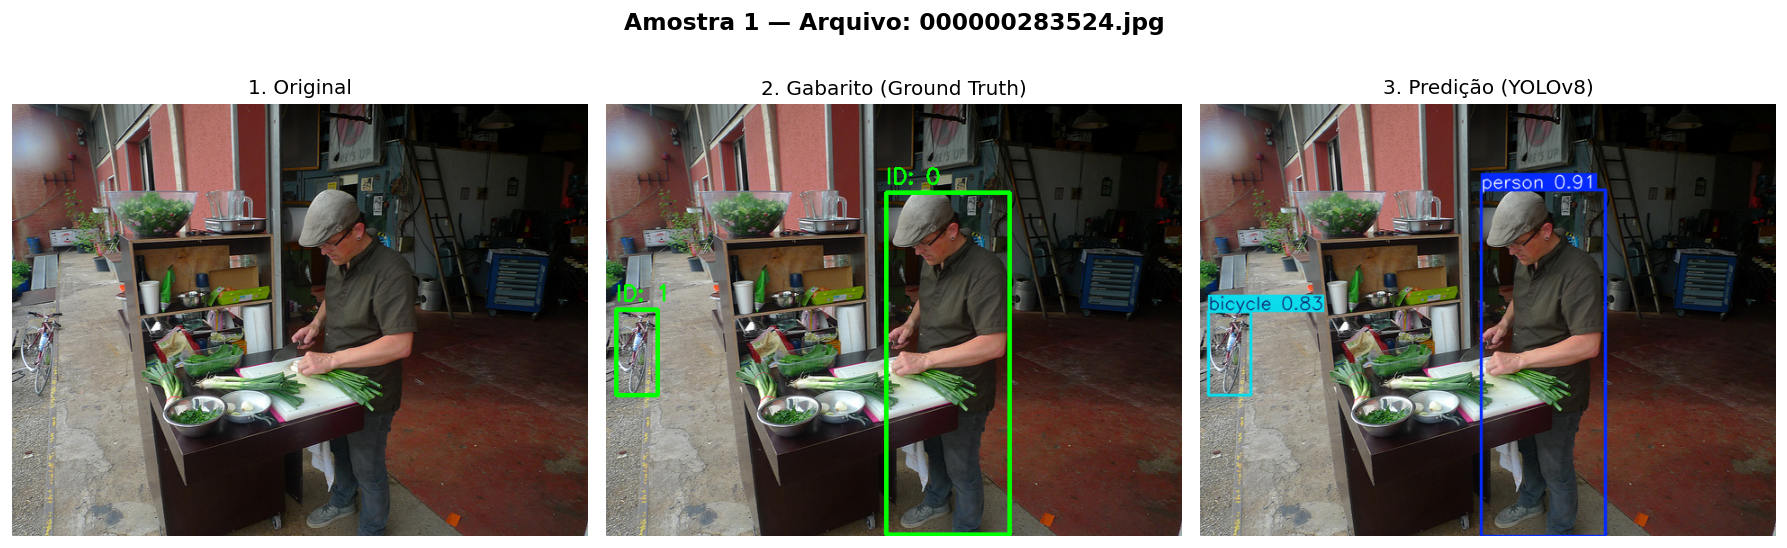

----------------------------------------------------------------------




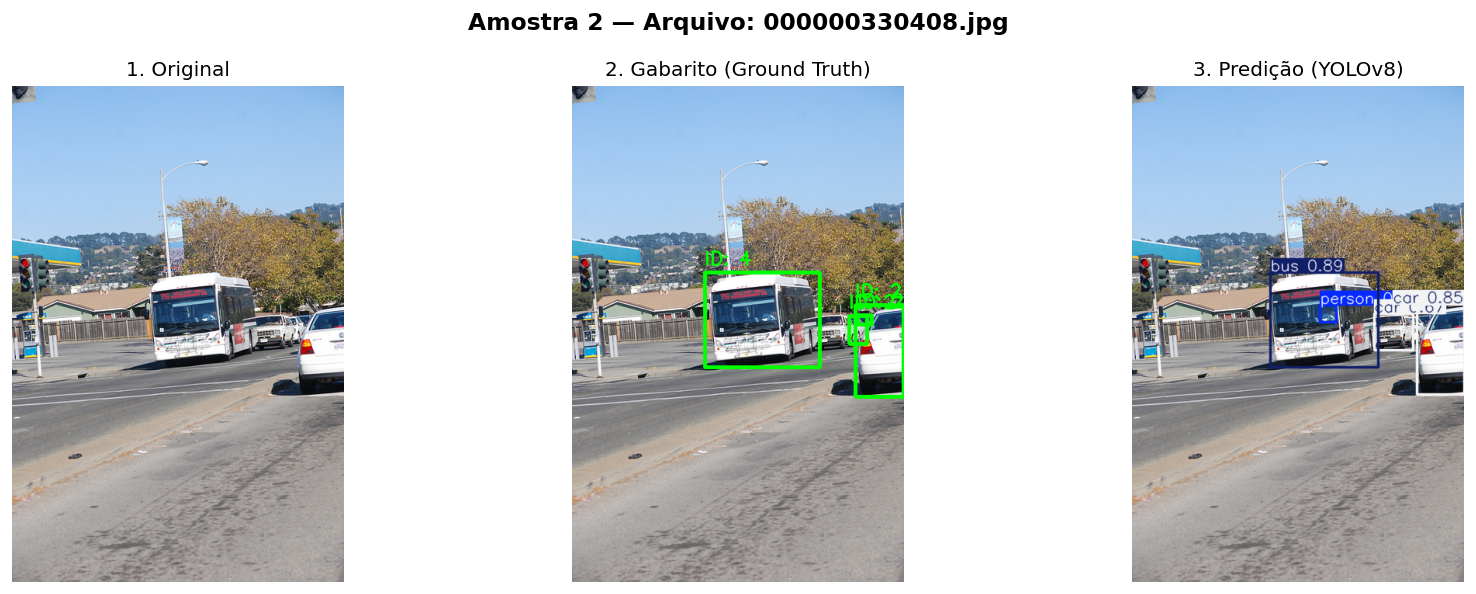

----------------------------------------------------------------------




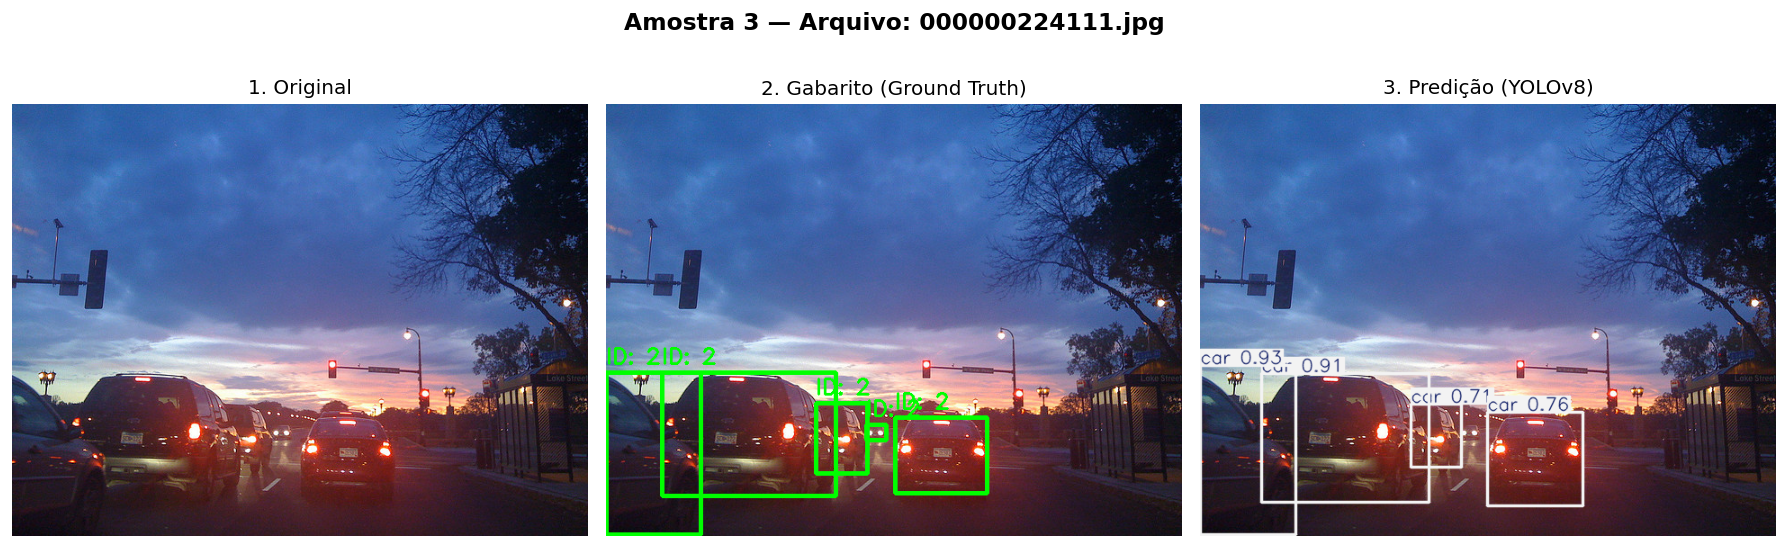

----------------------------------------------------------------------



✅ Processo comparativo do YOLOv8 finalizado com sucesso!


In [8]:
from IPython.display import display, Image
import matplotlib.pyplot as plt
import cv2
import os
import glob
import random
import datetime
from ultralytics import YOLO

print("\n>>> GERANDO AMOSTRAS COMPARATIVAS (YOLOv8)...")

# 1. Caminhos do Dataset e Modelo do YOLOv8
pasta_base_dataset = "/content/Yolo_dataset"
diretorio_imagens_teste = f"{pasta_base_dataset}/images/test"
diretorio_labels_teste = f"{pasta_base_dataset}/labels/test"
caminho_modelo = f"{pasta_treino_drive}/weights/best.pt"

if not os.path.exists(caminho_modelo):
    print(f"❌ ERRO: Arquivo best.pt não encontrado em: {caminho_modelo}")
else:
    # --- AUDITORIA DE GARANTIA: NOME, CAMINHO E HORA ---
    nome_arquivo_modelo = os.path.basename(caminho_modelo)
    hora_mod = datetime.datetime.fromtimestamp(os.path.getmtime(caminho_modelo)).strftime('%H:%M:%S de %d/%m/%Y')

    print("-" * 70)
    print("✅ AUDITORIA DO PESO UTILIZADO (YOLOv8):")
    print(f"📌 Nome:   {nome_arquivo_modelo}")
    print(f"📂 Caminho: {caminho_modelo}")
    print(f"🕒 Hora:   {hora_mod}")
    print("-" * 70)
    print("\n")

    # Carrega o modelo oficial do YOLOv8
    modelo_v8 = YOLO(caminho_modelo)

def desenhar_gabarito(img, caminho_label):
    h, w = img.shape[:2]
    if os.path.exists(caminho_label):
        with open(caminho_label, 'r') as f:
            for linha in f:
                partes = linha.strip().split()
                if len(partes) >= 5:
                    cls_id = int(partes[0])
                    cx, cy, bw, bh = map(float, partes[1:5])
                    x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
                    x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                    cv2.putText(img, f"ID: {cls_id}", (x1, max(y1-10, 20)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def mostrar_amostras_separadas_v8(dir_imgs, dir_labels, modelo_yolo, qtd_amostras=3):
    todas_imagens = glob.glob(f"{dir_imgs}/*.[jJ][pP][gG]") + glob.glob(f"{dir_imgs}/*.[pP][nN][gG]")
    if len(todas_imagens) < qtd_amostras:
        print(f"⚠️ Imagens insuficientes! Encontradas apenas {len(todas_imagens)}.")
        return

    amostras = random.sample(todas_imagens, qtd_amostras)

    for i, caminho_img in enumerate(amostras):
        nome_arquivo = os.path.basename(caminho_img)
        caminho_label = os.path.join(dir_labels, os.path.splitext(nome_arquivo)[0] + ".txt")

        # Processamento das imagens
        orig = cv2.cvtColor(cv2.imread(caminho_img), cv2.COLOR_BGR2RGB)
        gt = desenhar_gabarito(cv2.imread(caminho_img), caminho_label)

        # Inferência nativa do YOLOv8 com restrição estrita de confiança e iou
        resultados = modelo_yolo(caminho_img, conf=0.5, iou=0.5, verbose=False)
        # O .plot() do YOLOv8 retorna um array numpy BGR com as caixas desenhadas
        pred = cv2.cvtColor(resultados[0].plot(), cv2.COLOR_BGR2RGB)

        # Layout minimalista de 1 linha por amostra
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle(f"Amostra {i+1} — Arquivo: {nome_arquivo}", fontsize=14, fontweight='bold')

        axes[0].imshow(orig); axes[0].set_title("1. Original"); axes[0].axis('off')
        axes[1].imshow(gt);   axes[1].set_title("2. Gabarito (Ground Truth)"); axes[1].axis('off')
        axes[2].imshow(pred); axes[2].set_title("3. Predição (YOLOv8)"); axes[2].axis('off')

        plt.tight_layout()

        caminho_temp = f"/content/amostra_v8_{i+1}.png"
        plt.savefig(caminho_temp, bbox_inches='tight', dpi=120)
        plt.close()

        display(Image(filename=caminho_temp))
        print("-" * 70)
        print("\n")

if 'modelo_v8' in locals():
    mostrar_amostras_separadas_v8(diretorio_imagens_teste, diretorio_labels_teste, modelo_v8)

print("\n✅ Processo comparativo do YOLOv8 finalizado com sucesso!")